# Overdispersion -- Testing the Poisson Assumption on Real Data

Most cyber risk models count events with a Poisson distribution: one rate,
events independent of each other, variance equal to the mean. Part 0
introduced the negative binomial as the alternative when counts vary more
than that. This notebook does the test on real, public data and shows
where the simple test misleads.

The data:

- **CISA Known Exploited Vulnerabilities (KEV) catalog** -- new exploited
  CVEs per month, and the subset CISA marks as used in ransomware campaigns.
  A snapshot ships with the repository.
- **Ransomware.live** -- a public aggregator of ransomware leak-site
  postings, counted per month. Downloaded live when you run the notebook.

The causal lesson is the same one Part 3 keeps returning to: a variable you
did not model (here, a time trend) can produce the pattern you are testing
for. Growth looks like clustering until you separate the two.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

from decision_security.synth import make_rng, sample
from _data import load_kev, ransomware_monthly_counts

rng = make_rng(42)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PRIMARY = "#1A1A1A"
ACCENT = "#E74C3C"
DARK_BG = "#34495E"
LIGHT_GRAY = "#95A5A6"

# Analysis window (inclusive, YYYY-MM)
START = "2025-06"
END = "2026-05"
REFRESH_KEV = False   # True: download the current KEV catalog instead of the snapshot

MONTHS = pd.period_range(START, END, freq="M")
print(f"{len(MONTHS)} months: {MONTHS[0]} to {MONTHS[-1]}")

12 months: 2025-06 to 2026-05


## 1. Data

KEV entries are counted by the date CISA added them. Ransomware postings
are counted by the month Ransomware.live assigns them (its monthly endpoint
groups victims by attack date).

The KEV snapshot in `data/kev_snapshot.csv` keeps the notebook reproducible;
set `REFRESH_KEV = True` to use the current catalog. Both sources revise
their history (late postings, corrections), so a later run can give
slightly different numbers.

> **About the Ransomware.live data.** This notebook downloads it live from
> the free API every time it runs; the data is never stored in this
> repository. The free API is for personal, non-commercial use only and is
> rate limited, so the download waits and retries if needed. Do not
> republish the raw data, and credit "Source: Ransomware.live" when you use
> it. Terms: https://www.ransomware.live/t&c

In [2]:
kev = load_kev(refresh=REFRESH_KEV)
kev["month"] = kev["dateAdded"].dt.to_period("M")
kev_all = kev.groupby("month").size().reindex(MONTHS, fill_value=0)
kev_rw = (kev[kev["knownRansomwareCampaignUse"] == "Known"]
          .groupby("month").size().reindex(MONTHS, fill_value=0))

# Live download, cached in .cache/ (gitignored). Source: Ransomware.live, personal use only.
rw = ransomware_monthly_counts(MONTHS)

series = {
    "Ransomware leak-site postings": rw,
    "KEV new exploited CVEs": kev_all,
    "KEV ransomware-associated CVEs": kev_rw,
}
pd.DataFrame(series)

,Ransomware leak-site postings,KEV new exploited CVEs,KEV ransomware-associated CVEs
2025-06,549,20,1
2025-07,500,20,4
2025-08,528,15,1
2025-09,556,16,1
2025-10,791,31,3
2025-11,707,11,0
2025-12,761,20,2
2026-01,732,17,2
2026-02,784,28,2
2026-03,814,26,2


## 2. The Simple Test: Variance-to-Mean Ratio

For a Poisson process the variance equals the mean, so the
**variance-to-mean ratio** (VMR, the index of dispersion) is 1. The
dispersion test compares $(n-1)\cdot\text{VMR}$ with a $\chi^2_{n-1}$
distribution; a small p-value means the counts vary more than Poisson
allows.

In [3]:
def dispersion(counts):
    x = np.asarray(counts, dtype=float)
    n, mean, var = len(x), x.mean(), x.var(ddof=1)
    vmr = var / mean
    p = stats.chi2.sf((n - 1) * vmr, n - 1)
    return {"n": n, "mean": mean, "variance": var, "VMR": vmr, "p (Poisson)": p}


raw = pd.DataFrame({k: dispersion(v) for k, v in series.items()}).T
raw.round({"mean": 1, "variance": 1, "VMR": 2, "p (Poisson)": 4})

,n,mean,variance,VMR,p (Poisson)
Ransomware leak-site postings,12.0,689.9,14333.2,20.78,0.0000
KEV new exploited CVEs,12.0,21.3,41.2,1.93,0.0312
KEV ransomware-associated CVEs,12.0,2.5,5.4,2.15,0.0145


## 3. The Trap: Trend Looks Like Clustering

A growing series inflates the variance around its overall mean even if
arrivals around the trend are perfectly regular. The trend is an omitted
variable: leave it out and the test attributes its effect to clustering.

To separate the two, fit a Poisson regression with a time trend (log link)
and measure the dispersion that is left: the Pearson $\chi^2$ divided by its
degrees of freedom. Values near 1 mean "Poisson around the trend".

The negative binomial shape $k$ (the same $k$ as in Part 0; many texts call
it $r$) is then estimated two ways:

- **raw**: method of moments on the counts, $k = \text{mean}^2 / (\text{variance} - \text{mean})$;
- **detrended**: a negative binomial (NB2) regression with the same time trend, $k = 1/\alpha$.

Higher $k$ means the rate varies less (closer to Poisson); lower $k$ means
more clustering. $k$ measures rate variability, so it compares across
series; the VMR it produces depends on the mean (VMR = 1 + mean/$k$).

In [4]:
def detrended(counts):
    y = np.asarray(counts, dtype=float)
    t = np.arange(len(y))
    X = sm.add_constant(t)
    pois = sm.GLM(y, X, family=sm.families.Poisson()).fit()
    df = len(y) - X.shape[1]
    mean, var = y.mean(), y.var(ddof=1)
    k_raw = mean**2 / (var - mean) if var > mean else np.inf
    try:
        nb = sm.NegativeBinomial(y, X, loglike_method="nb2").fit(disp=0)
        alpha = nb.params[-1]
        k_det = 1 / alpha if alpha > 1e-8 else np.inf
    except Exception:
        k_det = np.nan
    return {"trend per month": np.exp(pois.params[1]) - 1,
            "dispersion after trend": pois.pearson_chi2 / df,
            "p (Poisson around trend)": stats.chi2.sf(pois.pearson_chi2, df),
            "NB shape k (raw)": k_raw,
            "NB shape k (detrended)": k_det}


det = pd.DataFrame({k: detrended(v) for k, v in series.items()}).T
det.style.format({"trend per month": "{:+.1%}", "dispersion after trend": "{:.2f}",
                  "p (Poisson around trend)": "{:.4f}", "NB shape k (raw)": "{:.1f}",
                  "NB shape k (detrended)": "{:.1f}"})

,trend per month,dispersion after trend,p (Poisson around trend),NB shape k (raw),NB shape k (detrended)
Ransomware leak-site postings,+4.2%,7.57,0.0000,34.9,129.7
KEV new exploited CVEs,+3.6%,1.74,0.0650,23.0,46.4
KEV ransomware-associated CVEs,+11.9%,1.67,0.0811,2.2,7.6


In [5]:
for name in series:
    print(f"{name}:")
    print(f"  VMR {raw.loc[name, 'VMR']:.2f} -> dispersion after trend "
          f"{det.loc[name, 'dispersion after trend']:.2f}   "
          f"(p around trend = {det.loc[name, 'p (Poisson around trend)']:.3f})")

Ransomware leak-site postings:
  VMR 20.78 -> dispersion after trend 7.57   (p around trend = 0.000)
KEV new exploited CVEs:
  VMR 1.93 -> dispersion after trend 1.74   (p around trend = 0.065)
KEV ransomware-associated CVEs:
  VMR 2.15 -> dispersion after trend 1.67   (p around trend = 0.081)


## 4. What It Looks Like

Grey band: the 95% range a Poisson process would produce. Left column:
around the overall mean. Right column: around the fitted trend.

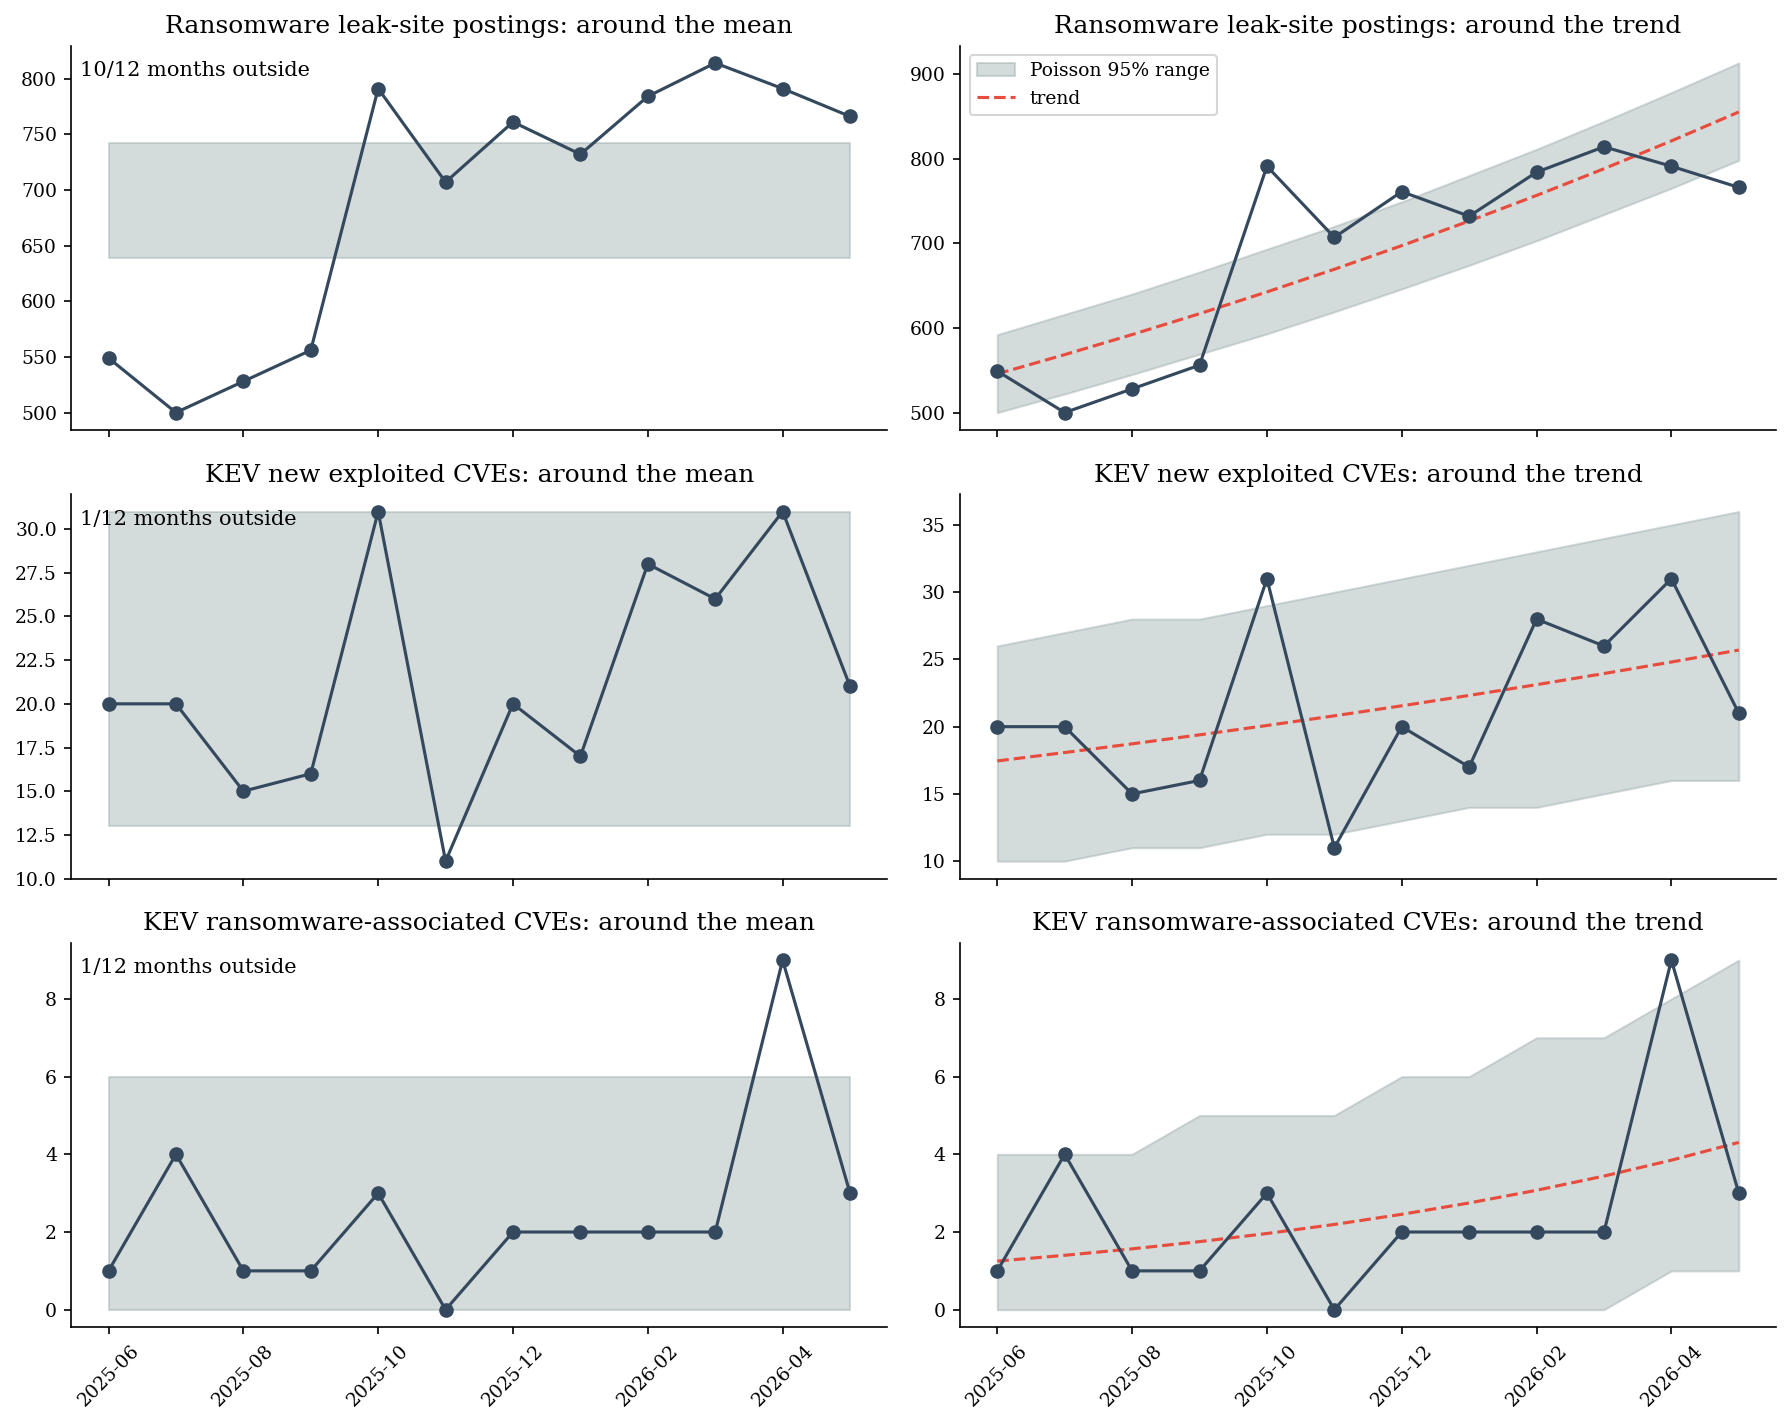

In [6]:
fig, axes = plt.subplots(len(series), 2, figsize=(12, 3.2 * len(series)), sharex=True)
x = np.arange(len(MONTHS))
labels = [str(m) for m in MONTHS]
for row, (name, s) in zip(axes, series.items()):
    y = s.values.astype(float)
    # around the mean
    lo, hi = stats.poisson.ppf([0.025, 0.975], y.mean())
    row[0].fill_between(x, lo, hi, color=LIGHT_GRAY, alpha=0.4, label="Poisson 95% range")
    row[0].plot(x, y, "o-", color=DARK_BG)
    row[0].set_title(f"{name}: around the mean")
    outside = int(((y < lo) | (y > hi)).sum())
    row[0].text(0.01, 0.92, f"{outside}/{len(y)} months outside", transform=row[0].transAxes)
    # around the trend
    fit = sm.GLM(y, sm.add_constant(x), family=sm.families.Poisson()).fit()
    mu = fit.fittedvalues
    row[1].fill_between(x, stats.poisson.ppf(0.025, mu), stats.poisson.ppf(0.975, mu),
                        color=LIGHT_GRAY, alpha=0.4, label="Poisson 95% range")
    row[1].plot(x, mu, "--", color=ACCENT, label="trend")
    row[1].plot(x, y, "o-", color=DARK_BG)
    row[1].set_title(f"{name}: around the trend")
for ax in axes[-1]:
    ax.set_xticks(x[::2])
    ax.set_xticklabels(labels[::2], rotation=45)
axes[0][1].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Why It Matters for a Risk Model

Same average rate, different clustering. The negative binomial is a Poisson
process whose rate itself varies: each year the rate is drawn from a Gamma
distribution with shape $k$ and mean equal to the long-run rate. Large $k$
recovers Poisson; small $k$ means some years are much worse than others.
The simulation compares the chance of a quiet year and of a bad year.

Note: this is not the same as a Gamma distribution for the time *between*
events. For inter-arrival times, shape 1 is Poisson, shape above 1 is *more
regular* than Poisson, and only shape below 1 clusters.

In [7]:
RATE = 3.0          # expected events per year for one organisation (illustrative)
YEARS = 200_000

sims = {
    "Poisson": sample("poisson", YEARS, rng=rng, lam=RATE),
    "Negative binomial, k = 30 (mild clustering)": sample("negbin", YEARS, rng=rng, mean=RATE, k=30),
    "Negative binomial, k = 2 (strong clustering)": sample("negbin", YEARS, rng=rng, mean=RATE, k=2),
}
table = pd.DataFrame({name: {"mean": v.mean(), "P(0 events)": (v == 0).mean(),
                             "P(>= 6 events)": (v >= 6).mean(), "P(>= 8 events)": (v >= 8).mean()}
                      for name, v in sims.items()}).T
table.round(3)

,mean,P(0 events),P(>= 6 events),P(>= 8 events)
Poisson,2.998,0.050,0.083,0.012
"Negative binomial, k = 30 (mild clustering)",3.008,0.056,0.094,0.017
"Negative binomial, k = 2 (strong clustering)",2.995,0.159,0.158,0.070


The mean barely moves, but the shape of the year does: clustered arrivals
produce more quiet years *and* more bad ones. A model that assumes Poisson
understates the right tail of the loss exceedance curve.

## 6. Pitfalls

**A high VMR is not proof of clustering.** A trend inflates the variance
around the overall mean. Remove the trend before reading the VMR as
burstiness, and keep the raw estimate only as a sensitivity case.

**Global series measure common shocks, not your organisation.** Once the
trend is removed, what is left comes mainly from common shocks (a campaign
wave or mass-exploited vulnerability raising many organisations' rates at
once) and batching (one campaign, many victims). Differences between
organisations don't show up in a global time series, and burstiness
specific to one organisation averages out. An organisation can measure its
own burstiness from its telemetry, if events are frequent enough to count.

**Know what is counted.** Leak-site postings are (mostly) successful attacks
on individual victims, closer to loss events than threat events; KEV entries
count newly exploited vulnerabilities, not attacks. Neither is an individual
attempt, so the parameters describe successful attacks and exploitation
waves.

**Twelve points is little data.** The tests have little power on 12 months:
a non-rejection after detrending is not proof of Poisson.

**Public sources are revised.** Both sources change their history and have
their own coverage gaps. Treat the parameters as a range for sensitivity
analysis, not as point values.

*Data: CISA KEV catalog (public domain). Source: Ransomware.live (free API,
personal use only; https://www.ransomware.live/t&c).*